# 2023年Java大厂面试｜03：MySQL优化、事务与分库分表

> 学习目标：能从接口慢的现象定位到具体SQL，解释索引为何有效或未被采用，讲清事务、MVCC与日志之间的关系，并说明主从复制和分库分表的收益与代价。

**主要依据：** `5.2023版Java面试教程/03-数据库篇/PPT/03-MySQL篇.pptx`，共91页。已读取全部文本、组合形状、表格与讲者备注，查看嵌入的SQL、执行计划、问答和示意图片。第90页是讲师介绍与课程推荐，第91页为空白。课程资料名为“数据库篇”，实际课件主题是MySQL。

配套目录有15节视频，仅核对标题，未观看或转写。`在线讲义文稿.txt`是一行飞书链接，已读取；在线页面能显示“面试专题”及“MySQL篇”目录，但点击后未显示MySQL正文，本篇没有将其正文作为已读来源。

“课件要点”表示原资料讲授内容；“补充说明”“修正”表示整理时补充的机制、适用条件或示例。课件混合使用MySQL 5.x和8.0相关表述，本篇以InnoDB为主要讨论对象，涉及8.0专属能力时单独注明。未逐项联网核验最新版本的默认参数。

### 目录

- 1～4：面试回答思路、慢查询定位、EXPLAIN、访问类型与Extra
- 5～8：体系结构与引擎、B+树、聚簇与二级索引、覆盖索引
- 9～14：深分页、游标分页、索引设计、最左前缀、索引未生效、SQL优化
- 15～22：ACID、隔离级别、RR与幻读、redo/undo、MVCC、ReadView、锁
- 23～27：主从复制、读写分离、拆分时机、拆分策略与路由问题
- 28～31：练习方案、面试自测、课件修正清单、来源与覆盖范围

所有SQL与命令都是学习示例，未执行数据库建表、数据写入、配置修改、复制部署或压力测试。课件中的“我们项目”、接口耗时和数据量是课程示例，不能直接写成自己的工作经历或实测结果。


## 1. 本篇知识路线与项目回答

**课件第2～3、17、35、38、46、89页：** 面试通常从项目使用方式切入，再追问底层原理。可以沿着以下顺序准备：

~~~text
接口为什么慢？
  → 哪条SQL慢、频率多高、扫描了多少行？
  → 执行计划怎么访问数据？
  → 索引结构与查询条件能否匹配？
  → 修改后是否保持结果与并发语义？
  → 单机优化仍不足时，如何复制、分离读写、拆分数据？
~~~

事务部分则沿着另一条线：业务必须满足什么约束 → 并发会破坏什么 → 隔离级别 → 快照读与锁定读 → MVCC和日志。

**补充回答模板：**

> 我在____学习/工作项目中处理____查询。表规模约____，关键条件是____，排序是____，返回____字段。通过____定位到SQL，用EXPLAIN看到____。调整____后，在相同数据、参数和负载下，____指标从____变为____。另外验证了____结果或并发边界。

没有真实优化数据时，可说明“在课程案例中分析了……，尚未完成压测”，不要填写课件截图中的秒数。项目用了MySQL，也不等于自己搭建过主从或分库分表。

**准备一条能被追问的SQL：** 画出表结构和现有索引，说明查询条件、排序规则、分页方式、数据分布，再解释为何选这个索引。只背“建索引、用缓存”无法说明原因。


## 2. 如何定位慢查询

**课件第4～8页：** 常见现象包括页面慢、接口压测响应长；常见SQL包括聚合、多表连接、大表查询和深分页。课程列出Arthas、Prometheus、SkyWalking以及MySQL慢查询日志。

**补充诊断顺序：**

1. 确认慢的是客户端、应用线程、连接池、数据库执行、锁等待、远程服务还是结果传输。接口慢不等于SQL一定慢。
2. 用链路追踪关联接口与数据库调用，保存SQL模板、参数范围、调用次数、执行时段及上下文。Prometheus通常提供指标，需要结合具体采集项；不能声称任意指标平台都能直接显示SQL全文。
3. 用慢日志或Performance Schema等数据库观测信息定位高耗时、高频率、扫描量大的SQL。
4. 再看执行计划、索引、数据分布和锁等待，提出能够解释现象的改动。

**课件配置示例，未应用：**

~~~ini
# my.cnf中示例配置
slow_query_log=1
long_query_time=2
~~~

`long_query_time`单位是秒，课件使用2秒作为教学阈值，默认值常见为10秒。实际阈值由接口目标和日志开销决定；低于2秒但每秒执行数千次的SQL也可能是重要瓶颈。

**补充只读检查示例，未执行：**

~~~sql
SHOW VARIABLES LIKE 'slow_query_log';
SHOW VARIABLES LIKE 'slow_query_log_file';
SHOW VARIABLES LIKE 'long_query_time';
SHOW VARIABLES LIKE 'log_output';
SHOW FULL PROCESSLIST;
~~~

课件中的`/var/lib/mysql/localhost-slow.log`是环境示例，实际路径取决于配置。修改配置文件后是否需要重启，取决于修改方式与参数；一些参数可动态设置，但GLOBAL值、当前连接值以及持久化配置的生效范围需要区分。不要为了排查直接重启生产数据库。

慢日志通常提供`Query_time`、`Lock_time`、`Rows_sent`、`Rows_examined`等字段。重点比较扫描行数与返回行数，以及总执行次数和累计耗时；不能只选耗时最长的一条，也不能只靠`Lock_time`排除所有InnoDB锁等待。

**面试回答：** 先说真实业务与观测证据，再说具体SQL，最后说如何分析和验证。课件截图的接口约2秒、文字示例约5秒均是案例，不能作为自己的测量结果。


## 3. EXPLAIN执行计划如何阅读

**课件第9～12页：** 在SELECT前加`EXPLAIN`或`DESC`，重点观察`possible_keys`、`key`、`key_len`、`type`和`Extra`。

~~~sql
-- 学习示例，未执行
EXPLAIN SELECT id, name FROM t_user WHERE id = 1;
~~~

| 字段 | 正确理解 | 阅读时的关注点 |
|---|---|---|
| id / select_type | 查询块与查询类型信息 | 子查询、派生表、UNION等结构 |
| table | 当前步骤访问的表或派生结果 | 联接访问顺序与每步输入 |
| partitions | 访问的分区 | 是否发生分区裁剪 |
| type | 访问方法 | 是否大量扫描，以及为何这样访问 |
| possible_keys | 优化器考虑的候选索引 | 有候选不代表最终采用 |
| key | 最终采用的索引 | PRIMARY、具体联合索引或NULL |
| key_len | 计划使用的索引键长度，单位字节 | 可辅助判断联合索引使用范围 |
| ref | 与索引列比较的常量或列 | 是否常量定位或连接匹配 |
| rows | 估计读取行数 | 普通EXPLAIN不是实际扫描量 |
| filtered | 估计经过条件筛选后的比例 | 配合rows观察后续输入规模 |
| Extra | 额外执行信息 | 覆盖、条件下推、排序、临时表等 |

**修正课件“key_len是索引占用大小”：** 它不是整个索引的磁盘体积，受使用的列、类型、字符集、长度和可空性等影响。课件第39页的303、309、612字节只对应课件表结构，不能拿来套用其他表。

**补充判断：** `key`非NULL说明计划采用某索引，但不代表所有条件都用于快速定位，也不代表性能一定好。`possible_keys`为NULL时，在一些覆盖扫描等计划中仍可能出现`key`；不要只看一列下结论。

普通EXPLAIN主要展示估算。MySQL 8.0.18起支持的`EXPLAIN ANALYZE`会实际执行其支持的语句并显示实际执行信息，**它会产生真实负载**；本篇没有运行。可先使用普通EXPLAIN，只有明确实验范围后再决定是否使用ANALYZE。

**回答思路：** 查询结构 → 采用的索引与访问方法 → 估计扫描量 → 是否回表、排序或临时结果 → 修改理由 → 同条件复测。不能用“出现回表”作为所有慢SQL的唯一解释。


## 4. type、Extra与容易误判的执行计划

**课件第10～12页：** 将常见访问方法按`NULL、system、const、eq_ref、ref、range、index、ALL`排列，作为面试入门记忆。

| type | 含义与常见场景 |
|---|---|
| NULL | 计划中无需实际访问表的情况，例如某些可直接计算的查询 |
| system | 特殊的单行表访问，是const的特例；不是“访问系统表”的通用代名词 |
| const | 用完整主键或唯一键与常量等值比较，最多定位一行 |
| eq_ref | 联接时对前一组合使用完整唯一键定位，通常最多匹配一行 |
| ref | 使用非唯一索引或唯一键前缀等值匹配，可能匹配多行 |
| range | 扫描一个或多个索引范围 |
| index | 扫描索引树，仍可能扫描很多条目 |
| ALL | 全表扫描 |

**修正：** 这是访问方法的经验顺序，不能替代成本分析。小表全表扫描可能合理；覆盖索引全扫描可能优于随机回表；`range`返回数百万行仍然可能慢。查询条件、数据量、行宽、缓存和联接次数都会改变成本。

| Extra | 意义 | 不能直接推出的结论 |
|---|---|---|
| Using index | 通常表示查询列可从所用索引获得，即覆盖访问 | 不等于扫描量小或绝无底层可见性检查 |
| Using where | 仍需应用WHERE过滤 | 不等于没有用索引 |
| Using index condition | 索引条件下推（ICP），先在引擎层利用索引条目过滤，再按需取整行 | 不等于覆盖索引，也不是“回表次数”的精确计数 |
| Using filesort | 排序未直接由所用索引顺序完成 | 不等于一定写磁盘；可能在内存排序 |
| Using temporary | 执行过程中使用内部临时结果 | 不等于所有临时表都在磁盘，也不等于语句一定不可接受 |

**面试关键区分：** 覆盖索引减少取整行的需求；ICP减少需要取整行的候选记录。二者解决的层次不同。

例如索引`(name,status,address)`，条件`name='小米科技' AND address='北京市'`可先通过name定位，再利用索引中的address过滤。跳过status并不意味着address从此毫无作用，只是一般不能接着用于连续等值前缀定位。


## 5. MySQL体系结构与存储引擎

**课件第13～16页：** MySQL分为连接层、服务层、引擎层、存储层。存储引擎负责数据存储、索引以及读取与更新，按表选择。

~~~text
客户端 / JDBC
  → 连接与认证
  → SQL解析、优化、执行等Server层能力
  → 存储引擎（如InnoDB）
  → 数据页、索引与相关文件
~~~

**补充：** 第14页是经典体系结构图，包含查询缓存。MySQL 8.0已移除Server层Query Cache，不能把图里的所有模块都当作8.0现状。Buffer Pool是InnoDB的页缓存，与旧Query Cache不同。

| 特性 | InnoDB | MyISAM | MEMORY |
|---|---|---|---|
| 事务 | 支持 | 不支持 | 不支持 |
| 主要锁能力 | 行级锁、表级意向锁等 | 表级锁 | 表级锁 |
| 外键约束 | 支持 | 不支持 | 不支持 |
| 数据存储特点（补充） | 数据持久存储，内存缓存数据页 | 数据与索引文件持久存储 | 数据位于内存，重启后数据丢失 |
| 典型索引（补充） | B+树、全文、空间等能力需按版本看 | B树类、全文等 | 支持HASH与BTREE，通常默认HASH |

InnoDB从MySQL **5.5.5起**成为默认引擎，支持事务、行锁和外键。业务需要事务并发控制时，通常首先讨论InnoDB。

**修正文件表述：**

- 旧版本常见`.frm`保存表定义；MySQL 8.0改用事务性数据字典，并有SDI等相关信息，不应简单说“把frm文件原样放进ibd”。
- 开启独立表空间等条件下，表通常有对应的`.ibd`，其中保存数据与索引等；InnoDB也支持共享系统表空间和通用表空间，因此不能说每张表必然独占一个ibd文件。
- 课件备注包含`ibd2sdi`命令，是查看SDI的环境示例，本篇未运行，也未读取用户数据库文件。

**面试回答：** 先说项目表使用的引擎，再比较事务、锁、外键和存储特点。不能把“内存存储”理解为MEMORY具备InnoDB一样的故障恢复能力。


## 6. 索引是什么，为什么常用B+树

**课件第18～22页：** 索引是帮助MySQL高效获取数据的数据结构。InnoDB常规索引使用B+树。课件比较二叉搜索树、红黑树、B树和B+树。

| 结构 | 优点 | 作为磁盘索引时要考虑的问题 |
|---|---|---|
| 二叉搜索树 | 搜索逻辑简单 | 可能退化成链，层数很高 |
| 红黑树 | 保持平衡 | 每个节点分支少，大量记录下层数仍较高 |
| B树 | 多分支，树较矮 | 非叶子和叶子都可能存数据，节点可容纳的键数量受数据大小影响 |
| B+树 | 内部节点负责导航，数据集中在叶子，适合顺序范围访问 | 索引也要维护，插入、更新、页分裂有成本 |

**核心解释：** 磁盘数据以页为单位读入。B+树的内部节点保存索引键和子页指针，通常能容纳较多分支，降低树高；叶子页保存实际索引记录，并按顺序连接，定位到范围起点后可继续扫描叶子。

**修正课件“非叶子只存指针”：** 内部节点还需要保存用于导航的键。主键索引的叶子保存行记录；二级索引叶子保存二级键和聚簇键等信息，不能说所有B+树叶子都是完整业务行。

索引可能帮助过滤，也可能在条件匹配时利用顺序减少排序、支持覆盖访问。它的收益取决于查询与索引结构是否匹配，不能保证所有带ORDER BY的查询都免排序。

**补充代价：** 更多索引占用空间和缓存，DML需要维护相关索引；索引列更新可能移动索引条目。主键较宽还会放大二级索引，因为二级索引携带聚簇键。

**面试简答：** B+树用高分支降低层数，把导航键和行数据分开，叶子按顺序连接，兼顾点查与范围扫描；它适合页式存储，并非因为“永远只读一次磁盘”。


## 7. 聚簇索引、二级索引与回表

**课件第23～26页：** InnoDB聚簇索引的叶子保存行数据；二级索引叶子保存对应主键。通过二级索引找到主键，再到聚簇索引查整行的过程叫回表。

| 项目 | 聚簇索引 | 二级索引 |
|---|---|---|
| 叶子核心内容 | 完整行记录（大字段等存储细节另论） | 二级索引键与聚簇键 |
| 数量 | 一张InnoDB表一个 | 可以有多个 |
| 常见查询 | 按主键定位行 | 按其他条件定位候选记录 |
| 取其他字段 | 定位到叶子即可取得行 | 不覆盖时通常继续按聚簇键取行 |

**聚簇键选择规则，补全课件条件：**

1. 有主键：使用主键。
2. 没有主键：使用第一个合适的、**所有列都为NOT NULL**的UNIQUE索引。
3. 没有上述键：生成隐藏聚簇键，常用名称`DB_ROW_ID`，通常6字节。

“非聚簇索引”等术语在不同数据库中实现可能不同。本篇讨论InnoDB二级索引；不能把“所有数据库二级索引都存主键”作为普遍结论。

~~~sql
-- 学习示例：假定id是主键，name上有二级索引
SELECT * FROM tb_user WHERE name = 'Arm';
~~~

~~~text
name索引定位Arm → 获得id，例如2 → id聚簇索引定位2 → 取行数据
~~~

**补充：** 若同名记录有多条，可能需要多次回表。回表不是错误，只是成本之一；如果返回大量记录，随机取行可能很贵。是否增加覆盖索引，应同时考虑索引维护开销和返回字段宽度。

**主键设计：** 稳定、较短、尽量减少随机插入造成的页分裂是常见原则。递增键有优势，但并不保证无热点；随机UUID、业务主键和分布式ID需要结合写入模式与实际设计比较。


## 8. 覆盖索引与索引条件下推

**课件第27～31、34页：** 查询所需要的列能从采用的索引获得，叫覆盖索引。它是查询与某个索引之间的关系，不是CREATE INDEX的一种独立语法。

假定`tb_user(id,name,gender,createdate)`中，id为主键，name有普通二级索引：

| 查询 | 通常的访问特点 |
|---|---|
| `SELECT * FROM tb_user WHERE id=2` | 直接访问聚簇索引获取行，无需再从二级索引回表 |
| `SELECT id,name FROM tb_user WHERE name='Arm'` | name索引携带id，通常可覆盖 |
| `SELECT id,name,gender FROM tb_user WHERE name='Arm'` | name索引没有gender，通常要回表 |

**修正：** 课件将主键查询完整行也标为覆盖。解释机制时，直接说“主键定位到聚簇叶子取得行”最清晰；面试讨论覆盖优化，常指利用较窄的二级索引减少访问聚簇行。

**补充示例，未执行：**

~~~sql
CREATE INDEX idx_user_name_gender ON tb_user(name, gender);
EXPLAIN SELECT id, name, gender FROM tb_user WHERE name = 'Arm';
~~~

因为二级索引同时携带id，上述查询通常可从该联合索引取得所需字段。但实际计划受数据、成本、版本影响，不能在没执行时声称Extra一定是什么。

覆盖要考虑查询需要的字段，包括过滤、输出等，不是只看SELECT列中有没有“单列索引”。多个独立单列索引也不等于自动形成一个覆盖联合索引。前缀索引只保存字符串前缀，通常不能覆盖完整字符串。

**ICP与覆盖对比：**

~~~text
覆盖访问：从索引记录获得查询所需信息，通常省去取整行
ICP：先用索引中可判断的条件筛掉候选，剩余候选再按需取整行
~~~

InnoDB做MVCC可见性检查等时，某些二级索引访问仍可能读取聚簇记录。因此工程表达宜用“减少回表或取整行需求”，不要承诺任何场景下绝不访问聚簇索引。


## 9. 超大分页与延迟关联

**课件第32～34页：** `LIMIT 9000000,10`随着偏移量增加会变慢。截图显示普通查询约11.05秒，改写后几次结果约7.13、7.37、7.19秒；这些仅是课件环境观察，本篇未复现。

**修正“必须排序9000010条”：** 如果计划已能按索引顺序访问，不一定发生额外排序。深分页的共性是要找到并跳过前面的大量记录，只返回最后少量记录；是否排序另看ORDER BY及计划。原始示例不写ORDER BY，也不保证稳定的分页顺序。

**课件的延迟关联思路，补上明确顺序：**

~~~sql
-- 学习示例，未执行
SELECT t.*
FROM tb_sku AS t
JOIN (
    SELECT id
    FROM tb_sku
    ORDER BY id
    LIMIT 9000000, 10
) AS page_ids ON page_ids.id = t.id
ORDER BY t.id;
~~~

先在子查询里只取得少量最终ID，再取得完整行。这能减少中间过程复制或取整行的成本，但**偏移扫描仍存在**。如果子查询扫描的是宽的聚簇叶子，而非更紧凑的二级索引，收益也可能有限。不能把它解释为直接跳到第900万行。

**补充业务示例：** 列表按状态与时间过滤时，可考虑`(status,created_at,id)`索引，先从较窄索引获得id，再关联行；需要保持过滤条件、排序、权限条件和分页范围一致。

必须使用完整、确定的ORDER BY。外层JOIN不会自动继承子查询排序，应在外层明确排序。若按时间排序且时间可重复，增加id作为稳定的次序；并发新增或修改下，偏移分页仍可能重复或漏项。

**面试回答：** 深分页可能扫描并丢弃大量记录；延迟关联降低取整行成本，游标分页避免大偏移。能否随机跳页、排序条件是什么，决定可选方案。


## 10. 游标分页与稳定排序（补充）

本节是对深分页的补充，课件主要讲覆盖索引加子查询。

若业务只要求“下一页”，可以携带上一页最后一项的排序键：

~~~sql
-- 按唯一递增id分页，学习示例，未执行
SELECT id, name
FROM tb_user
WHERE id > :last_id
ORDER BY id
LIMIT 10;
~~~

它通常可从索引边界开始扫描，无需跳过900万条记录。适用于分页浏览和分批导出，但无法直接满足任意页码跳转；总数统计也不是免费得到的。

按`created_at DESC,id DESC`排序时，要携带两个字段，并准备相应索引，例如`(status,created_at,id)`：

~~~sql
-- :参数是应用绑定参数的表示，不是可直接粘贴执行的完整SQL
SELECT id, created_at, title
FROM tb_article
WHERE status = :status
  AND (created_at < :last_created_at
       OR (created_at = :last_created_at AND id < :last_id))
ORDER BY created_at DESC, id DESC
LIMIT 10;
~~~

排序字段尽量稳定。仅携带时间会在相同时间的记录上出现边界错误；使用`<`或`>`由排序方向决定。页面权限和过滤条件也必须跟随游标校验，不能把任意游标当成访问授权。

**并发边界：** 游标分页也不是天然一致快照。排序键被更新、记录被删除、不同页使用不同快照时，结果仍可能变化；若业务要求一次导出严格一致，需另行设计快照或固定查询范围，并评估长事务代价。

**选择表：**

| 需求 | 常见方案 | 代价 |
|---|---|---|
| 小偏移、任意跳页 | OFFSET/LIMIT | 偏移变大时成本增长 |
| 任意跳页、行很宽 | 延迟关联 | 减少取行成本，仍扫描偏移 |
| 连续下一页 | 游标分页 | 需要传游标，跳页不直接支持 |
| 批量处理全表 | 按稳定键分批读取 | 需处理并发变化、续传和失败重试 |


## 11. 索引创建原则与业务设计

**课件第35～37页：** 围绕WHERE、ORDER BY、GROUP BY创建索引，考虑区分度、前缀索引、联合索引、索引数量和NOT NULL。

**修正“必须超过10万才建索引”：** 没有统一的10万行门槛。主键、唯一性约束、小表高频查询等可能更早需要索引；很大的表也可能有不适合索引的低选择性查询。应看访问模式、数据分布和收益。

| 设计因素 | 如何判断 |
|---|---|
| 查询频率与重要性 | 优先优化频繁执行、累计成本高或关键链路的查询 |
| 条件与排序 | 联合考虑等值过滤、范围、排序、分页和返回列 |
| 区分度 | 唯一值多通常有利，但最终要看具体条件匹配多少行 |
| 联合索引顺序 | 常用等值前缀、后续范围/排序与其他查询复用之间权衡 |
| 字段宽度 | 短键节省空间与缓存，但不能牺牲正确语义 |
| 前缀索引 | 节省长字符串空间，但区分度、完整值判断与覆盖能力受限 |
| 索引数量 | 评估写入开销、空间、冗余与使用情况 |
| NULL约束 | 由业务语义决定是否NOT NULL；B+树也能索引NULL值 |

**补充案例，未执行：**

~~~sql
-- 示例查询：用户某状态订单，按时间和id稳定分页
SELECT id, created_at, amount
FROM tb_order
WHERE user_id = :uid AND status = :status
ORDER BY created_at DESC, id DESC
LIMIT 20;

-- 候选索引，只是设计示例
CREATE INDEX idx_order_user_status_time
ON tb_order(user_id, status, created_at, id);
~~~

是否把amount加入以覆盖查询，要比较节省回表与索引变宽、amount更新开销；是否把status放前面，要看其他常用查询。不能只机械地按“区分度最高永远放最左”排序。

**补充：** `(a,b)`可能覆盖只按a过滤的一部分用途，但不能因此直接删除原a索引；窄索引可能有成本优势，唯一约束也可能不同。删除前需观察实际使用与约束。

添加索引可能影响写入与DDL过程，本篇未对用户数据库做任何变更。面试回答用一条SQL解释设计理由，比逐条背规则更有效。


## 12. 联合索引与最左前缀

**课件第38～41页：** `tb_seller_index(name,status,address)`用于说明最左前缀。联合B+树按列顺序做字典序排列：先按name，同name内再按status，同name/status内再按address。

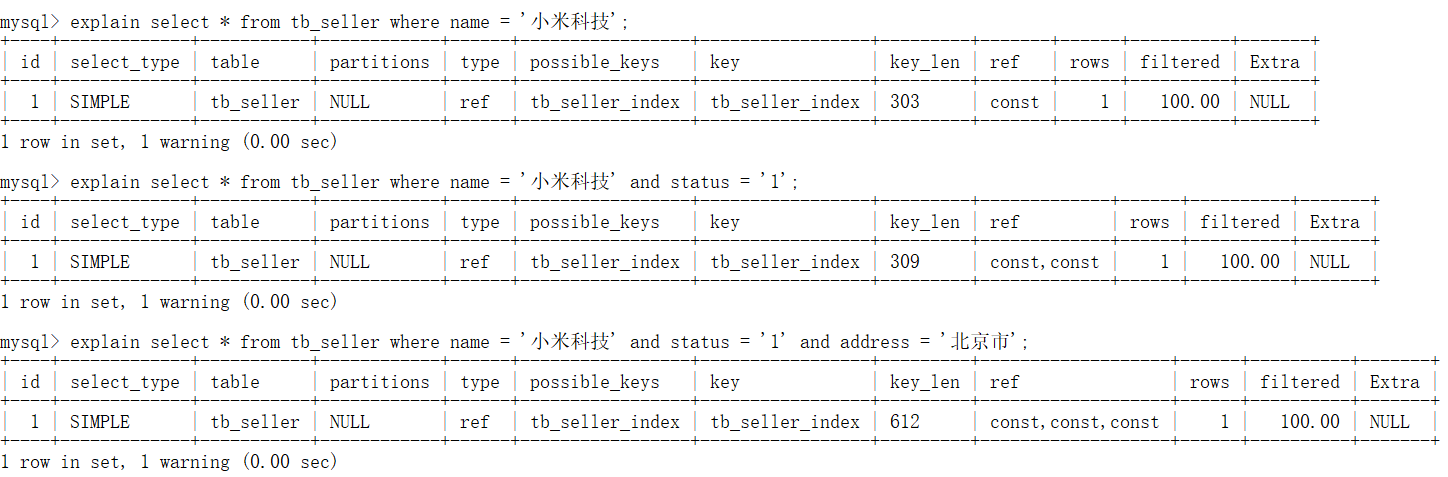

截图观察：只约束name时`key_len=303`，再加status时为309，加address时为612。数字是课件环境结果，核心是使用的键前缀变化。

| 条件示例 | 一般定位特点 |
|---|---|
| `name='A'` | 使用name前缀 |
| `name='A' AND status='1'` | 使用name/status前缀 |
| 三列都是等值条件 | 有机会使用完整等值前缀 |
| `status='1' AND address='B'` | 缺少最左name，通常不能按普通前缀直接定位 |
| `name='A' AND address='B'` | name可定位；跳过status后address一般不继续构成连续定位前缀 |
| `name='A' AND status>'1' AND address='B'` | name加status范围；address仍可能参与ICP或其他过滤 |

**重要修正：**

- 最左前缀说的是**索引列顺序**，不是WHERE里书写条件的顺序。`status='1' AND name='A'`不因文字顺序而失去name/status匹配。
- 跳过中间列通常会截断连续定位前缀，但整个索引仍可能被使用，后续列也可能用于过滤或覆盖。
- “范围条件右边的索引全部失效”过度简化。应区分构造扫描边界、过滤、覆盖与排序；`>`、`>=`、BETWEEN等边界以及版本优化可能表现不同，最终看计划。
- MySQL 8.0的部分查询可使用Index Skip Scan等优化，缺少首列也不是任何场景都必然全表扫描。

**回答模板：** 联合索引有序方式决定可连续利用的前缀；具体条件能定位哪些范围，用`key`、`key_len`、访问方法和Extra判断，不能把所有未用于定位的列都称为“索引完全失效”。


## 13. 什么情况下索引没有发挥预期作用

**课件第38～45页：** 五类典型情况是最左前缀不匹配、范围后的列、列上运算、字符串类型转换、前导百分号LIKE。

| 课件案例 | 原因 | 常见改法与边界 |
|---|---|---|
| 缺少联合索引首列 | 普通B+树前缀难以直接定位 | 按高频查询重新设计；仍可能覆盖扫描、Skip Scan等 |
| 跳过中间列或遇范围 | 连续等值定位前缀受限制 | 区分定位和ICP，不能说整棵索引失效 |
| `SUBSTRING(name,3,2)='科技'` | 对列计算后的值不等于原索引排序值 | 保持列可直接比较；若业务必须计算，可考虑支持版本中的函数索引/生成列 |
| 字符串列与数字比较 | 对字符串列发生转换时可能无法有效定位 | 应用绑定与列类型一致；不是所有隐式转换都失效 |
| `name LIKE '%黑马程序员%'` | 任意起点匹配不能直接确定常规B+树前缀范围 | 前缀查询或符合业务的全文/搜索方案；语义不同不能随意替换 |
| `name LIKE '黑马程序员%'` | 有固定前缀，通常可构造范围 | 是否采用仍受字符集、排序规则、数据与成本影响 |

**课件截图的细节：** 第43页name条件仍在，`status='0'`时键长度309，改成数字`status=0`后键长度303，仍使用name前缀并显示`Using index condition`。这是**部分条件未用于定位**，不是整条语句完全没有使用索引。

**补充日期示例，未执行：**

~~~sql
-- 对created_at做函数运算，普通原列索引通常难以直接范围定位
SELECT id FROM tb_order WHERE DATE(created_at) = '2026-10-10';

-- 在日期/时间类型与业务时区允许时，改写成半开区间
SELECT id FROM tb_order
WHERE created_at >= '2026-10-10 00:00:00'
  AND created_at <  '2026-10-11 00:00:00';
~~~

查询TIMESTAMP、DATETIME的时区规则不同，改写要确保同一业务日期。函数索引是版本相关能力，不是无需验证就能使用的通用替代。

**另一类情况：** SQL可利用索引，但匹配记录太多、表很小、统计信息不准确或随机回表成本较高，优化器主动选择ALL。索引存在与优化器选择索引是两件事。

**排查顺序：** 看实际列类型与绑定参数 → 查看索引列顺序 → EXPLAIN判断使用部分 → 看数据分布与扫描量 → 改写或调整索引 → 检查结果等价并在相同负载下测量。本篇没有获取实际执行计划，因此示例不附虚构的性能结论。


## 14. SQL优化经验与语义约束

**课件第46～49页：** 优化分为表设计、索引、SQL写法、主从读写分离、分库分表。

| 优化层次 | 做什么 | 必须保留的条件 |
|---|---|---|
| 表与类型 | 合理选择tinyint/int/bigint、char/varchar，减少无用宽字段 | 数值范围、精度、字符集与业务含义正确 |
| 索引 | 对准过滤、排序、联接、分页，减少冗余 | 唯一约束、写入成本和查询复用不能忽略 |
| SQL | 明确输出列，避免无谓扫描、函数转换、重复查询 | 改写前后结果、重复行、NULL与排序语义一致 |
| 访问模式 | 批量查询、避免N+1，控制返回量与长事务 | 不能用超大IN列表或事务换来新的瓶颈 |
| 架构 | 读写分离、缓存、拆分、异步处理 | 需要处理延迟、一致性与失败恢复 |

**需要修正的课件简化：**

- `UNION ALL`保留重复，`UNION`默认去重。只有业务允许重复或已能证明无重复时，才可以替换；性能更好不能凌驾于结果正确。
- `INNER JOIN`与`LEFT/RIGHT JOIN`结果不同，不能只为性能改成内连接。内连接可以由优化器重排；外连接的顺序有语义限制，但在满足条件时也可能被简化或优化，不能说永远无法调整。
- “小表驱动大表”是某些嵌套循环联接下的经验。应比较**过滤后的输入规模**、索引和联接算法；MySQL 8.0还可能使用Hash Join等，不能仅按原表总行数选顺序。
- `CHAR`不必然比`VARCHAR`快。定长/变长、字符集、行宽、更新与实际引擎实现都会影响结果。金额常使用合适精度的DECIMAL，不能因为字节少改成会丢精度的类型。
- `SELECT *`不总是错误，但业务接口只取需要的列，通常能减少传输、序列化、取整行及对表结构的耦合。不要为“所有查询都覆盖”给每列建索引。

**补充验证记录表：**

| 项目 | 调整前 | 调整后 |
|---|---|---|
| SQL与参数 | 待记录 | 待记录 |
| MySQL版本、隔离级别与配置 | 待记录 | 保持一致或注明变化 |
| 表行数、数据分布、索引 | 待记录 | 待记录 |
| 计划与扫描量 | 待记录 | 待记录 |
| p50/p95/p99、吞吐、错误率 | 待测 | 待测 |
| 结果校验与并发行为 | 待验证 | 待验证 |

“待测”不是测试结果。本篇只整理方法。优化案例应解释证据如何支持结论，不能只说加一个索引后“明显变快”。


## 15. 事务与ACID

**课件第51～53页：** 事务是一组作为整体提交或撤销的操作。转账示例：张三与李四原各2000，转1000后分别1000与3000，总额保持4000。

| 特性 | 含义 | 转账对应 |
|---|---|---|
| Atomicity 原子性 | 事务修改作为整体提交或回滚 | 扣款与入账不能只成功一半 |
| Consistency 一致性 | 事务使数据满足定义好的业务与数据库约束 | 总额守恒、账户约束等成立 |
| Isolation 隔离性 | 并发事务按所选隔离规则控制相互影响 | 其他事务如何看到中间或已提交状态 |
| Durability 持久性 | 已提交事务的效果按持久化保证在故障后保留 | 成功提交后有恢复保障 |

**修正：**

- 持久性重点是**提交后的效果**，课件“提交或回滚后数据改变都永久”容易让人误解。回滚撤销该事务的未提交修改，不是把其业务变更永久保留。
- 一致性不是所有字段数值相同，也不是多个数据库副本实时同步。数据库约束和事务机制帮助保持规则，正确的业务逻辑同样必要。
- 隔离性并不表示任何级别下都完全不受并发影响；不同隔离级别允许的可见性不同。

**学习伪代码，未执行：**

~~~text
开启事务
  UPDATE账户A：有足够余额时扣1000；检查受影响行数
  UPDATE账户B：加1000；检查受影响行数
  任一步不符合预期：ROLLBACK并报告失败
  全部满足业务条件：COMMIT
~~~

**补充：** 把两句UPDATE包在事务里仍要检查余额、账户存在、幂等和错误路径；事务不能自动发现“扣错了人”。连接中断后的提交结果可能未知，重试前需靠业务唯一请求号等确认。

MySQL通常默认autocommit开启，单条语句可各自成为事务。`START TRANSACTION`建立多语句事务；一些DDL有隐式提交规则，不能承诺任意CREATE/ALTER都能与DML一起回滚。Java的事务边界与回滚规则可在后续框架篇继续讨论。


## 16. 并发事务问题与隔离级别

**课件第54～59页：** 脏读、不可重复读、幻读是常见问题；四种级别是RU、RC、RR和Serializable。MySQL InnoDB常见默认是RR，但实际实例或会话可能被修改。

| 问题 | 主要关注 | 时间线例子 |
|---|---|---|
| 脏读 | 读取他人未提交的修改 | B写余额但未提交，A读到；B后续回滚 |
| 不可重复读 | 同一记录再次读，值发生变化 | A读余额100；B改200并提交；A再读变200 |
| 幻读 | 同一条件查询的结果集合变化 | A查某范围；B在范围插入并提交；A再次查出现新行 |

**修正幻读定义：** “查不到，插入却提示已存在”是课件展示现象之一，涉及快照可见性与唯一约束检查的差别。通用定义是范围查询结果集合变化，而不是只能以插入报错形式出现。

以下是SQL隔离级别的通用入门表，“可能”表示该级别允许该异常，不代表每次都会出现：

| 隔离级别 | 脏读 | 不可重复读 | 幻读 |
|---|---|---|---|
| READ UNCOMMITTED | 可能 | 可能 | 可能 |
| READ COMMITTED | 不允许 | 可能 | 可能 |
| REPEATABLE READ | 不允许 | 不允许 | 通用标准仍允许；InnoDB实际机制见下一节 |
| SERIALIZABLE | 不允许 | 不允许 | 不允许 |

**补充只读检查示例，未执行：**

~~~sql
-- MySQL 8.0等支持该变量的环境
SELECT @@transaction_isolation, @@autocommit;
~~~

旧版本变量名可能不同，需要按版本核对。RR讨论“同一事务多次读”，如果每次SELECT都以autocommit形成新事务，不能要求它们共享同一个快照。

**修正“级别越高性能必然越低”：** 更强的约束可能增加等待或冲突，但实际吞吐由查询、冲突程度和实现决定。Serializable不等于整个数据库全局只能跑一个事务，而是并发执行结果应等价于某种串行顺序。

**补充遗漏的业务问题：** 丢失更新、写偏差、先查再写等，不应只靠背三类异常就认为全部解决。需要配合条件更新、行锁、唯一约束或更高隔离策略。


## 17. InnoDB的RR、快照读与幻读

**课件第58～59页的表按通用隔离级别列出RR仍有幻读。补充InnoDB实际行为：** 需要区分普通一致性读、锁定读与混合读写，不能无条件说“RR完全解决”或“RR完全不解决”幻读。

| 操作模式 | RR下主要机制 | 解释边界 |
|---|---|---|
| 同一事务内连续普通SELECT | 通常复用首次一致性读建立的ReadView | 后续他人提交的新行通常不可见 |
| 范围SELECT ... FOR UPDATE等 | 按访问路径使用记录锁、间隙锁/Next-Key Lock等 | 合适范围内阻止冲突插入，范围由索引和实际扫描决定 |
| 普通SELECT后再UPDATE或锁定读 | 后者是当前读，行为不同于旧快照 | 可能接触到旧快照未包含的已提交记录 |

**补充时间线：**

~~~text
A开启RR事务，普通SELECT范围 → 建立快照，得到已有记录
B插入范围内一行并COMMIT
A再次普通SELECT同范围 → 通常仍看旧快照
A改用锁定读或UPDATE → 当前读，不能假定仍等于旧快照
~~~

还要考虑A自己的写入：一致性读可以看到自身修改，可能出现“自己修改后的数据 + 其他行的旧版本”的组合。RR读到的结果不必等于数据库曾出现过的某个全局物理状态。

**为什么查不到却插入重复？** 旧快照中看不到B后来提交的行，不意味着唯一性检查允许重复键。写入和约束检查要维护当前数据的约束，因此可能报重复键。应处理数据库错误，而不是把快照查询当成唯一性保证。

**RC区别：** 每次一致性读建立新ReadView，下一次普通SELECT可以看到在两次读之间提交的数据。RC通常减少很多范围间隙锁，但外键检查、重复键检查等仍有特殊锁行为。

**面试回答：** InnoDB RR下，快照读通过MVCC稳定读视图；锁定范围读通过相应锁约束并发插入。要说明读法、访问索引、事务边界，混合当前读与快照读不能用一句“绝无幻读”概括。


## 18. Buffer Pool、redo log与undo log

**课件第60～64页：** Buffer Pool缓存数据页，修改首先作用于内存中的页，再异步刷脏页。InnoDB默认页大小常见为16KiB，可受初始化配置等影响。

| 项目 | 主要作用 | 不能混淆的点 |
|---|---|---|
| Buffer Pool | 缓存数据页、索引页等，减少重复磁盘I/O | 是内存区域，不是持久化承诺 |
| redo log | 记录页修改相关的重做信息，用于崩溃恢复 | 不是主从复制的核心日志，也不是只记录已提交事务 |
| undo log | 保存回滚所需信息，并支持构造历史版本 | 不是实际保存一段反向SQL字符串 |
| binlog（补充） | Server层逻辑变更日志，用于复制等 | 与InnoDB redo的目标和内容不同 |

**redo与WAL：** 数据页可以稍后落盘，但在把对应脏页持久化之前，要先满足重做日志持久化的要求。崩溃后可利用redo恢复页修改，再处理未提交事务的回滚等。提交不要求把所有修改的数据页立即刷到表文件。

**修正课件“事务提交时才记录redo”：** 修改过程中会产生redo；提交时的日志写入/刷盘行为受配置控制。redo可包含未提交事务的修改信息，崩溃恢复还需要事务状态和undo，不是把所有redo当成已提交业务结果。

**undo：** 插入、更新、删除产生相应回滚信息。可把它理解为撤销修改所需的旧值或操作信息，但不等于日志文件里写一条完整INSERT/DELETE。第63页问答截图“删除记录产生delete逆操作”写反了；正文第62页的逆操作概念更接近教学意图，实际实现应理解为undo记录。

插入undo通常在事务结束后不再为其他事务提供旧行版本；更新/删除相关历史信息可能仍被活跃ReadView需要，清理由purge等机制推进。长事务可能使版本保留时间变长，增加空间和遍历成本。

**补充参数边界：** `innodb_flush_log_at_trx_commit`影响redo在提交时的写与刷盘策略，常见值1侧重每次提交刷盘；binlog持久化还与`sync_binlog`等有关。操作系统、存储设备及配置会影响故障保证，不能用“有redo就绝不会丢任何提交”作无条件承诺。

课件`ib_logfile0/1`是旧式布局示例，较新MySQL版本的redo文件组织可能不同。不要按课件文件名直接查找、修改或删除实际实例文件。

**ACID对应：** undo支持原子回滚，redo支持持久性，锁与MVCC支持隔离；一致性还依赖业务正确性及约束，不能只由undo单独“保证”。


## 19. MVCC、隐藏字段与版本链

**课件第65～70、78页：** MVCC是Multi-Version Concurrency Control，多版本并发控制。InnoDB通过记录隐藏字段、undo版本信息和ReadView，决定普通一致性读能看到哪个版本。

| 隐藏字段 | 含义 | 补全课件条件 |
|---|---|---|
| DB_TRX_ID | 最近插入或修改此聚簇记录的事务ID | 是记录版本的修改事务标识，不是每条SQL的新编号 |
| DB_ROLL_PTR | 指向undo相关记录的回滚指针 | 可通过undo信息构造更早版本 |
| DB_ROW_ID | 在无合适聚簇键时使用的隐藏行ID | 无主键但有合适NOT NULL唯一键时，不必生成隐藏聚簇键 |

MVCC主要依托InnoDB聚簇记录相关信息实现；二级索引记录布局和可见性处理还有其他细节，不能说任意引擎、任意记录都同样包含这些字段。

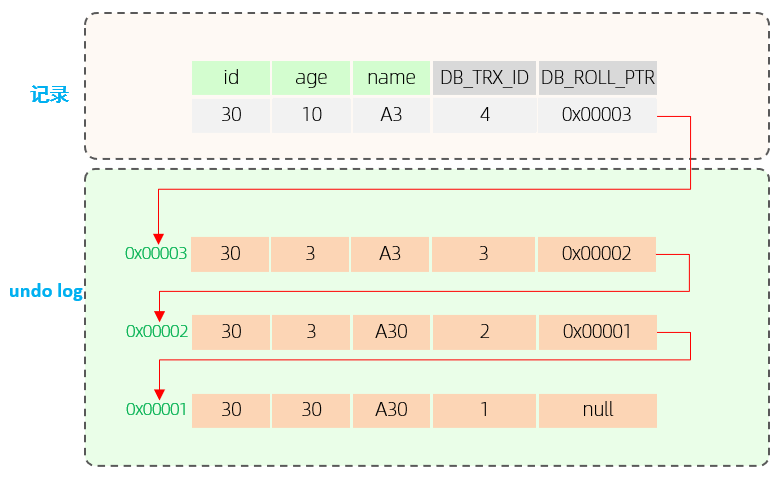

课件演示id=30：

~~~text
当前记录：trx_id=4，age=10，name=A3
  → 可构造旧版本：trx_id=3，age=3，name=A3
  → 可构造旧版本：trx_id=2，age=3，name=A30
  → 可构造旧版本：trx_id=1，age=30，name=A30
~~~

这是逻辑示意；实际undo不是必须保存每个完整业务行的独立拷贝，也不是每次SELECT就复制整张表。删除记录可涉及删除标记和后续purge，不能说提交时旧版本立即全部物理删除。

**读取流程：** 从当前版本开始，按ReadView判断是否可见；不可见则沿undo信息查找更早版本；找到第一个满足规则的版本，或判断该行在快照中不存在。

**修正“使读写没有冲突”：** MVCC减少普通一致性读与写之间的阻塞，不代表所有读写和写写都无冲突。UPDATE、锁定读仍可能等待锁；长事务仍会保留大量历史信息。

**面试简答：** 版本链回答“这行有哪些旧状态”，ReadView回答“这次读能用哪个状态”。二者要结合，而不是仅说“MVCC就是undo log”。


## 20. ReadView的字段与可见性规则

**课件第71～73页：** ReadView记录创建时相关的活跃事务信息，供一致性读选择版本。

| 课件字段名 | 含义 |
|---|---|
| m_ids | 创建读视图时仍活跃的相关读写事务ID集合；不同实现描述对创建者是否列入可有差别 |
| min_trx_id | 最小活跃事务ID，对应可见性低边界 |
| max_trx_id | 当时尚未分配的下一事务ID，对应不可见性高边界 |
| creator_trx_id | 创建此读视图的事务标识，用于识别自身修改 |

上表是课件命名，用于学习规则；源码名称和“上/下限”的叫法可能不同，不应只按字段名字推断边界方向。

**判断某个记录版本的修改事务ID `v`，规则如下：**

1. `v == creator_trx_id`：自身修改，通常可见。
2. `v < min_trx_id`：在该读视图活跃边界之前已提交，可见。
3. `v >= max_trx_id`：在读视图建立时尚未分配的事务，不可见。
4. `min_trx_id <= v < max_trx_id`：若在`m_ids`中，创建视图时仍活跃，不可见；若不在，说明已提交，可见。
5. 不可见时沿版本链继续判断；没有符合条件的版本，视图中就没有这行。

**修正课件第73页：** 高边界应为`>=`，不是只用`>`；中间区间右端应为`< max_trx_id`。版本上的`trx_id`指修改这个版本的事务，不是“查询当前事务ID”。

**教学伪代码：**

~~~text
visible(v, view):
  若v属于当前事务：可见
  若v < view.min：可见
  若v >= view.max：不可见
  否则：当v不在view.active_ids中时可见
~~~

**边界例子：** 假定`creator=5,min=3,max=6,active={3,4,5}`，则版本2可见；版本3和4不可见；版本5因自身修改可见；版本6不可见。即使事务3在视图建立后提交，旧视图也不会因此把3从其创建时集合里“自动删掉并更新”。

只读事务可能延迟分配读写事务ID等，空活跃集合也有实现规则。这些不影响入门的可见性判断，课件并未展开源码细节，本篇不把简化字段表冒充完整实现。


## 21. RC与RR的ReadView时机

**课件第71、73～78页：** RC每次一致性读创建ReadView；RR通常在第一次一致性读创建，后续复用。RR的普通`BEGIN/START TRANSACTION`并不必然立刻建立快照；`WITH CONSISTENT SNAPSHOT`等情况另看版本和隔离级别。

沿用课件版本链，A是读事务5：

| 时刻 | 发生的事 | 可见性解释 |
|---|---|---|
| t1 | 事务2已提交；3、4活跃；A第一次读 | view活跃集合含3、4，当前4不可见，版本3也不可见，读到版本2：age=3,name=A30 |
| t2 | 事务3提交，事务4仍未提交；A第二次读 | RC创建新view，3可见，读到age=3,name=A3；RR复用旧view，仍读版本2 |
| t3 | 事务4也提交；A再次读 | RC的新view可以读到4：age=10,name=A3；RR在同一事务且未自身修改时仍读旧可见版本 |

课件第74～77页的RC读视图依次显示活跃集合`{3,4,5}`与`{4,5}`，并用RR复用旧视图作对比；这是课堂简化例子。

**快照读与当前读：**

| SQL | 常见分类 | 主要行为 |
|---|---|---|
| 普通非锁定SELECT（RC/RR） | 一致性读/快照读 | 按ReadView读取可见版本，通常不获取行锁 |
| SELECT ... FOR UPDATE | 锁定读/当前读 | 按锁定读取语义取当前记录并加相应锁 |
| SELECT ... FOR SHARE（8.0） | 共享锁定读 | 与写锁协调；旧写法常见LOCK IN SHARE MODE |
| UPDATE / DELETE等 | 写操作的当前读取与锁控制 | 不按原普通快照直接覆盖旧版本 |

**修正：** 当前读不是读取其他事务未提交的任意脏数据，可能等待锁后处理当前版本；加锁范围也不仅是最后返回的一行。普通SELECT也不是所有隔离级别和所有SQL上下文下都不加锁，例如Serializable需要另外解释。

**常见追问：** 为什么RR中同一事务UPDATE后SELECT结果能变？因为自身修改可见，写操作使用当前状态和锁控制；“可重复读”不能机械理解为包括自己写入在内的所有结果永久不变。

**记忆：** RC“每次读重新观察已提交状态”；RR“同一事务复用首次一致性读的视图”。前提是同一事务、相同读法，且考虑自身修改。


## 22. 行锁、间隙锁与业务并发控制（补充）

课件第64、71、78页提到排他锁、共享锁和MVCC，但未系统展开锁类型。本节补充用于衔接事务追问，具体锁范围需要通过版本、隔离级别、索引与实际计划判断。

| 锁 | 主要作用 |
|---|---|
| 共享锁S | 允许兼容的共享读取，限制冲突修改 |
| 排他锁X | 排斥冲突的共享/排他锁请求，协调修改 |
| Record Lock | 锁索引记录 |
| Gap Lock | 约束索引记录间的间隙，主要阻止冲突插入 |
| Next-Key Lock | 记录锁与相邻间隙锁的组合，用于范围并发控制 |
| 意向锁IS/IX | 表级标记事务计划持有的行级锁，帮助协调表/行锁 |

**重要边界：** 一个事务持有X锁，不代表其他事务普通一致性读一定被阻塞；快照读可能读历史版本。行锁以索引记录为基础，未走合适索引可能扫描并锁住更多记录，但不能把所有这种情况都简单叫“自动升级成表锁”。

RR下完整唯一索引等值定位已存在的唯一记录时，通常可只用记录锁；非唯一范围和不存在记录等场景不同。RC下很多间隙锁行为减少，外键和唯一性检查等有例外。别把“where id=某值”当成任何条件下都只锁一行。

**条件更新比先查后改更可靠：**

~~~sql
-- 学习示例，未执行；检查受影响行数是否为1
UPDATE tb_stock
SET stock = stock - 1
WHERE id = :sku_id AND stock > 0;
~~~

这把“库存足够”与扣减放在一条修改语句里，并由引擎锁控制并发；还需要与订单创建、幂等、事务提交结果和失败重试一起设计。

**锁定读流程示例：** 事务中按明确索引`SELECT ... FOR UPDATE`，检查业务条件，完成相关修改后提交。要缩短事务，不在持锁时做慢网络请求；多个事务按统一顺序获取锁，有助于减少死锁。

死锁并不说明事务失效，InnoDB可检测并选择事务回滚。应用需要识别可重试错误、回滚整个业务事务，再在幂等前提下有限重试；不是任意异常都无限重试。


## 23. MySQL主从复制原理

**课件第79～81页：** 主从复制核心是binlog。课程流程：主库记录变更 → 从库读取binlog写入Relay Log → 从库重放事件。

~~~text
应用写入主库
  → 主库binlog事件
  → 主库发送线程提供事件
  → 从库接收线程写Relay Log
  → 从库应用线程/工作线程执行事件
  → 从库数据推进到对应位置
~~~

课件称接收端为I/O Thread，应用端为SQL Thread。较新版本的术语常使用source/replica，且可并行应用，不能认为永远只有一个串行应用线程。

| 日志 | 层次与用途 | 典型保存内容 |
|---|---|---|
| redo log | InnoDB崩溃恢复 | 页修改相关重做信息 |
| undo log | InnoDB回滚与历史版本 | 撤销修改/构造旧版本所需信息 |
| binlog | MySQL Server复制、变更记录与恢复链路 | 语句或行变更事件，取决于格式 |
| relay log | 从库接收并等待应用的事件 | 从主库获取的复制事件 |

**修正“binlog记录所有DDL/DML语句”：** binlog开启且没有被过滤或禁用等条件下，会记录相关变更事件；`STATEMENT`记录语句，`ROW`主要记录行变更，`MIXED`按条件选择。普通SELECT/SHOW不作为一般数据变更写入binlog，但不能把binlog描述成任何情况下都是SQL全文日志。

**补充一致提交机制：** InnoDB redo与Server层binlog需要在提交时协调，通常用内部两阶段提交等机制，减少崩溃后两套日志不一致；这不是跨业务数据库的分布式事务协议，也不表示主从实时强一致。

**补充定位方式：** 复制可以按文件/位置或GTID管理进度。GTID有助于标识和管理事务，不能消除复制延迟，也不自动保证任意故障切换无数据丢失。

默认常见复制模式为异步。半同步可让提交与至少一个从端收到/持久化相应事件的确认关联，但确认时点与配置、版本有关，通常不表示该事件已经在从库应用完毕。

**面试简答：** binlog发送、从端落Relay Log、应用线程重放是复制链路；redo解决本机引擎恢复。复制进度、延迟和故障切换是下一层问题。


## 24. 读写分离与复制延迟（补充边界）

**课件第48、79、82页：** 写请求进入主库，读请求进入从库，用复制同步数据。它可以分担读压力，也可能减少读写资源争抢。

**修正：** 读写分离不会自动减少主库写入负载，从库应用日志也需要CPU与I/O；它不能直接修复慢SQL和错误索引。单纯增加副本并不保证任何读都更快。

**写后读问题：**

~~~text
用户下单 → 主库事务提交 → 立即查订单 → 路由到从库
                                        从库尚未应用 → 订单暂时查不到
~~~

| 业务要求 | 常见处理 | 代价或条件 |
|---|---|---|
| 必须马上看到刚写结果 | 相关读走主库，或提交后返回已知业务结果 | 需要明确哪些读必须强新鲜 |
| 会话内短期一致 | 在约定流程内保持主库路由 | 固定时间窗口不能保证任何延迟都已消除 |
| 要确认某提交已到从端 | 依据复制位点/GTID等待并设置超时，失败时回主库等 | 实现与版本、路由支持相关 |
| 允许少量陈旧 | 从库读取并明确新鲜度目标 | 监控延迟，定义业务可接受范围 |

以上为补充方案，不表示课程系统已实现。不能把“写完睡1秒”当成可靠一致性协议。

**事务边界：** 同一个业务事务内，读取与写入需要使用一致的连接与路由策略；把每条SELECT任意分散到不同副本，可能破坏事务预期。

**运维观测：** 区分接收延迟、应用积压、应用线程错误与长事务。单一“延迟秒数”指标可能不完整，不能仅凭显示0就保证所有用户读取一定看到最新提交。

主从复制提供副本，但不等于备份：误删除也可能复制到从库。备份、时间点恢复、故障切换与读取路由是不同能力，需要分别设计和演练，本篇未部署或演练。


## 25. 什么时候考虑分库分表

**课件第82、89页：** 业务持续增长，索引、查询、主从读写分离等优化仍不能解决I/O、网络、CPU或连接压力时，考虑拆分。资料给出“单表1000万或20G”作为经验量级。

**修正：** 1000万行、20GB不是强制门槛。宽行、热点、查询类型和服务目标会改变瓶颈；同样1000万行，有的索引查询很稳定，有的聚合已很贵。需要指标支持拆分理由。

**拆分前分析：**

1. 是容量、随机I/O、CPU计算、并发连接、锁竞争、写热点，还是缺少索引与无界查询？先定位具体资源。
2. 是否可以通过索引、SQL、合理字段、归档、缓存、批处理、扩容或读副本满足近期目标？
3. 主键与查询条件能否稳定路由到一个分片？业务是否经常跨用户、跨订单范围查询？
4. 是否能承担数据迁移、校验、双写/切换、扩容、故障恢复和跨分片一致性的工程成本？

**不要混淆：**

- 同实例内分成多张表，可能减少单表规模，但没有增加独立机器的CPU、内存或总I/O能力。
- MySQL分区表与应用层分片不同。分区裁剪要求匹配相关条件，也不能自动获得跨实例扩展。
- 读写分离侧重分担读访问；水平分片可分散存储和部分读写压力，但是否均匀取决于分片键。

**补充决策记录：** 写清瓶颈指标、预计增长、拆分候选键、主要查询的分片覆盖率、热点风险以及迁移方案。没有这些证据时，先做实验验证，不直接把“数据多”当结论。

**面试表达：** 自己没有做过拆分，可说掌握了策略与代价，在课程设计中分析过场景；不可按课件要求“想一个大业务”后写成真实工作经历。


## 26. 垂直拆分与水平拆分

**课件第83～87页：** 垂直拆分按业务或字段，水平拆分按记录。

| 策略 | 拆分依据 | 课件例子 | 实际收益与限制 |
|---|---|---|---|
| 垂直分库 | 业务领域/表 | 用户、订单、商品各自数据库 | 独立资源和管理边界；跨库事务与关联更复杂 |
| 垂直分表 | 字段/冷热/大字段 | SKU常用字段与description拆开 | 核心行变窄；取完整对象可能多一次查询或JOIN |
| 水平分库 | 同类记录按规则路由 | 订单按id范围或取模到多个库 | 分散存储与访问；需处理跨片与扩容 |
| 水平分表 | 同表记录分到多个物理表 | `tb_order_0/1/2` | 降低单表规模；同实例资源仍共享 |

**垂直分库：** 应按领域边界建立数据归属，避免所有服务随意跨库访问。把表搬进多个库并不自动形成合格的微服务架构，还需要接口、事务与变更边界。

**垂直分表：** description、TEXT、BLOB等大字段或低频字段放附表，主表保留列表常用字段。需要定义一对一键和删除/更新关系，评估反而增加的联接与一致性成本。课件“两表互不影响”应理解为部分资源争用减少，并非物理和业务上绝对独立。

**水平分库：** 表结构相近、数据分布到独立实例时，可能增加整体资源，缓解单节点瓶颈。仍需处理路由、均衡、复制、备份和某片故障；拆分后不是自动可用性更高。

**水平分表：** 课件说“减少锁表几率”较笼统。InnoDB行级锁冲突取决于访问索引、事务和热点行，不会仅因表大就必然锁整表；分片可隔离部分访问，但同一热门记录仍可能竞争。

**组合策略：** 可以先按领域垂直分库，再在订单领域内水平拆分。不要将两个方向互相替代，也不要只记“分库解决压力、分表解决存储”的口号。


## 27. 分片键、路由与拆分后的问题

**课件第86～89页：** 使用`id%3`或ID范围路由；拆分后出现分布式事务、跨节点关联、分页排序、主键重复等问题。提到ShardingSphere和MyCat作为中间件例子。

| 路由方式 | 适合点 | 需要考虑 |
|---|---|---|
| 哈希/取模 | 有机会较均匀分布 | 3扩为4时大量映射改变，迁移复杂；热门键仍热点 |
| 范围 | 范围查询和按时间归档较自然 | 最近范围可能热点，数据量不一定均衡 |
| 业务键 | 常见查询可单片完成，例如user_id | 查询是否都带该键，单用户热点与跨用户报表 |
| 映射表/逻辑槽（补充） | 可调整物理映射，支持迁移管理 | 路由元数据、可用性与一致性更复杂 |

**分片键选择：** 数据分布、主要查询、写入分布、稳定性、关联关系一起评估。仅保证ID唯一不表示路由正确；ID生成信息是否含路由要按方案设计，不能凭Snowflake名称推断。

**跨分片问题：**

- **事务：** 跨片订单与库存操作不再由一个本地事务自动覆盖。根据业务选择跨库事务协议、业务补偿或其他方案，并明确失败和重试语义；中间件名称不能代替协议解释。
- **关联：** 订单与明细尽量按相同键绑定到同片，或使用适当冗余/汇总。跨片JOIN可能需要多节点取数与合并，不是完全不可能，而是成本和支持限制更大。
- **排序分页：** 没有分片键时可能广播；每片取候选后全局归并，深分页代价更高。需要稳定排序，不能简单把各片第10页拼在一起。
- **聚合：** SUM/COUNT可在满足语义时局部汇总；AVG需要总和与总数，不能直接平均各片平均值；DISTINCT和全局排名可能更复杂。
- **唯一性：** 每片局部UNIQUE不自动保证全局唯一，手机号/订单号等约束需要专门设计。
- **扩容：** 涉及迁移、路由切换、增量追赶、校验和回退。不能仅改`%3`为`%4`就完成扩容。

**中间件边界：** ShardingSphere、MyCat有不同架构与版本能力，SQL、事务、迁移和数据库兼容范围需要核对。本篇未安装或验证任何中间件，不声称二者对所有问题都透明解决。

**面试回答模板：** 业务瓶颈 → 拆分方向 → 分片键与路由理由 → 常见查询如何落片 → 跨片代价 → ID/一致性/扩容方案 → 自己实际负责的范围。


## 28. 学习实验设计与记录（尚未执行）

以下是可自行在隔离测试库开展的练习清单，不是本篇已完成的实验。使用明确的MySQL版本、测试数据和两个独立连接，记录结果，不在生产库直接尝试。

### A. 执行计划与联合索引

准备`id`主键，以及`(name,status,address)`联合索引。使用相同SELECT列，依次比较：

~~~sql
EXPLAIN SELECT * FROM demo_seller WHERE name='A';
EXPLAIN SELECT * FROM demo_seller WHERE name='A' AND status='1';
EXPLAIN SELECT * FROM demo_seller
WHERE name='A' AND status='1' AND address='B';
EXPLAIN SELECT * FROM demo_seller WHERE status='1';
EXPLAIN SELECT * FROM demo_seller WHERE name='A' AND address='B';
EXPLAIN SELECT * FROM demo_seller
WHERE name='A' AND status>'1' AND address='B';
~~~

只给小表12条数据可能让优化器选择全扫描，不能据此推断规则错误。记录表定义、字符集、统计信息与数据分布，再解释`type/key/key_len/rows/Extra`。这些语句尚未运行。

### B. 覆盖与ICP

对同一过滤条件比较返回`id,name`和返回完整行。再使用存在于联合索引后续列的过滤，观察ICP。目标是说明“取整行需求”和“候选数量”分别如何变化，不预先要求每次都出现相同Extra。

### C. 深分页

比较同一确定排序下的浅页、大OFFSET、延迟关联、游标分页。保持数据、缓存冷热、连接和负载条件相近；检查结果顺序与边界。延迟关联仍扫描偏移，不能只记录单次秒数后声称任意场景都加速。

### D. RC/RR双连接

~~~text
连接A：开启事务，普通SELECT记录初始值
连接B：修改同一记录并COMMIT
连接A：再次普通SELECT；记录结果；结束事务
分别使用RC与RR，保持其他条件相同
另一次实验：连接A在第二次读改用FOR UPDATE，观察差别
~~~

修改会话隔离级别要在合法时机，并保证每轮事务结束。RR测试必须在同一事务里，不能让两个SELECT各自自动提交；锁定读实验应设置合理等待与清理步骤。

### E. 手算ReadView

给定`creator=5,min=3,max=6,active={3,4,5}`，依次判断2、3、4、5、6，再沿课件链`4→3→2→1`寻找第一个可见版本。正确答案：2可见，3/4不可见，5为自身可见，6不可见；链上先命中2。

### F. 分片设计练习

用20个虚构ID分别计算`id%3`和`id%4`，观察映射变化；再设计按user_id落片的订单/明细表，列出不带user_id的搜索与报表如何处理。不要编造已经上线过某中间件的经历。

每个实验记录“预期、实际、差异原因、版本、未解决问题”。本篇所有记录状态均为未执行，没有性能测量、部署或故障恢复结果。


## 29. 高频面试自测与回答骨架

以下答案是本篇知识的压缩提纲，先回答主干，再按追问展开。项目经历只用自己的真实材料。

| 问题 | 回答主干 | 常见追问 |
|---|---|---|
| 如何定位慢查询？ | 从接口观测关联具体SQL，结合慢日志、频率、扫描量与等待分析 | 阈值怎么设，接口慢是否一定是SQL慢 |
| EXPLAIN看什么？ | key/前缀、type、估计rows、Extra及联接结构 | key_len与索引体积不同，估计与实际不同 |
| 为何用B+树？ | 多分支减少层数，内部键导航，叶子顺序适合范围访问 | B树区别、页大小、索引维护成本 |
| 什么是回表？ | 二级索引获得聚簇键后继续取行 | 返回量大为何贵，覆盖与ICP区别 |
| 覆盖索引是什么？ | 查询所需字段可由所用索引取得 | 主键隐含字段、前缀索引限制 |
| 超大分页如何优化？ | 解释偏移扫描，延迟关联减少取行，游标避免大OFFSET | 稳定排序、任意跳页、并发变化 |
| 索引如何设计？ | 按高频SQL的等值、范围、排序与返回列设计 | 区分度、冗余、写入和空间代价 |
| 索引为何未采用？ | 条件与结构不匹配、列计算/转换、前导LIKE，或成本选择 | 是否全部失效、ICP、Skip Scan |
| ACID分别是什么？ | 整体提交、业务约束、并发可见性、提交持久化 | 日志与锁如何支持，业务逻辑责任 |
| 默认隔离级别？ | InnoDB常见默认RR，查实际会话配置 | autocommit、RC与RR读取差异 |
| RR解决幻读吗？ | 区分快照读、锁定范围读与混合读写 | Next-Key、唯一检查、自身修改 |
| redo和undo区别？ | redo用于恢复页修改，undo用于撤销和旧版本 | binlog区别、刷盘配置、长事务 |
| 解释MVCC？ | 隐藏字段关联undo版本链，ReadView决定可见性 | 边界>=、RC/RR生成时机 |
| 主从复制原理？ | binlog→接收→Relay Log→应用 | 异步延迟、GTID、并行复制、故障切换 |
| 何时分库分表？ | 单机优化仍不满足容量或性能目标，有指标和查询分析 | 没有固定千万行门槛 |
| 拆分有哪些策略？ | 垂直按业务/列，水平按记录落库/表 | 事务、JOIN、分页、唯一、扩容 |

**MVCC回答示例：**

> InnoDB的一致性读用MVCC减少读写阻塞。聚簇记录的事务ID和回滚指针关联undo历史版本，ReadView保存创建时的事务可见性边界，从当前版本沿链寻找可见版本。RC每次一致性读重新建视图，RR通常在同一事务首次一致性读建立并复用；自身修改可见。锁定读和写入使用不同的当前读取与锁机制，所以MVCC不代表所有操作无锁。

**SQL优化回答示例：**

> 在____场景中，通过____观测定位到____查询。执行计划显示____，结合数据分布判断主要成本是____。调整____，保持结果与排序一致，再在相同条件下比较____指标。读写分离与拆分只有在查询和单机优化不足时才纳入，并补充一致性与迁移方案。

**自测标准：** 能指出假设、解释失败边界、识别课件中过度简化的结论，并能给出对应验证方法。不会的追问明确说明未实践范围，再解释已掌握的机制。


## 30. 课件修正与版本提醒清单

以下集中记录会影响面试准确性的差别，正文已在相应章节展开。它们是整理者补充，不表示课件逐字包含这些说明。

| 课件简化表述 | 建议使用的准确表达 |
|---|---|
| key_len是索引占用大小 | 是计划使用键长度，不是索引总磁盘大小 |
| system表示系统表，const仅主键查询 | system是特殊单行访问；const可来自完整主键或唯一键常量等值 |
| Using index condition表示用了索引并回表 | 核心是ICP先筛索引条件；不等于覆盖，也不提供精确回表次数 |
| 非叶子只存指针 | 内部节点保存导航键和子页指针 |
| 无主键就用第一个唯一索引 | 还要求该唯一索引所有列NOT NULL等合适条件 |
| 无主键必有DB_ROW_ID聚簇键 | 存在合适唯一非空键时可用它 |
| 每表必然一个ibd，8.0把frm合入ibd | 表空间组织可不同；8.0使用事务性数据字典和SDI等机制 |
| 超大分页一定排序所有跳过记录 | 可能索引有序访问；共性是大偏移扫描与丢弃 |
| 覆盖+子查询彻底解决深分页 | 减少取整行成本，OFFSET扫描仍在 |
| 超过10万才建索引 | 无统一门槛，按约束、访问模式和成本设计 |
| 范围右侧字段完全失效 | 区分范围定位、ICP、覆盖和排序；看实际计划 |
| 隐式转换必定使整个索引失效 | 看转换方向和列类型，可能只影响部分键前缀 |
| UNION ALL可直接替换UNION | 重复语义不同，只有结果要求允许才替换 |
| 用INNER JOIN替换外连接就更快 | 先保证结果语义；驱动顺序与算法由实际计划决定 |
| CHAR必然比VARCHAR快 | 看内容、字符集、行宽与实现，不作无条件判断 |
| RR永远解决不了/完全解决幻读 | 分清一致性读、锁定范围读、混合读写与自身修改 |
| 持久性包括回滚后的业务变更永久 | 提交的事务效果按持久化机制保留；回滚撤销未提交修改 |
| redo只在提交时产生 | 修改过程中产生，提交写/刷盘受配置影响 |
| undo保存反向SQL且单独保证一致性 | 保存回滚/旧版本信息；一致性还需业务与约束 |
| 读视图高边界只检查大于max | 应使用`v >= max`，中间范围为`min <= v < max` |
| MVCC使所有读写没有冲突 | 主要减少一致性读阻塞；写写与锁定读仍受锁协调 |
| binlog总是所有DDL/DML原SQL | 记录相关变更事件，语句/行格式和配置决定内容 |
| 主从等于实时强一致或备份 | 有复制延迟；误操作可传播，备份需另行设计 |
| 1000万或20G就必须分库分表 | 是课程经验量级，决策应以具体瓶颈与目标为依据 |
| 分表自动减少行锁热点 | 锁依赖索引与访问；同一热点行仍可能竞争 |

**版本提醒：** 旧体系结构图含Query Cache，8.0已移除；旧文件示例含frm和`ib_logfile0/1`，较新版本布局不同；FOR SHARE、函数索引、EXPLAIN ANALYZE、Skip Scan、Hash Join等要按实际版本与查询条件核对。

不需要在每个回答里把所有修正列一遍，但被追问时要能解释适用条件。代码语法、表名和示例参数也不能当成用户真实环境。


## 31. 来源、课件覆盖与后续学习

### 已读取资料

主课件：`03-数据库篇/PPT/03-MySQL篇.pptx`，91页。完整读取文本、组合形状、表格及备注；53张去重后的嵌入图片已按缩略总览检查，并将关键SQL、执行计划、版本链和问答截图单独查看。两张有学习价值的原课件图片已内嵌到本Notebook，不依赖外部图片文件。

| 课件范围 | 原资料主题 | 本篇位置 |
|---|---|---|
| 1～3 | MySQL篇与课程路线 | 导言、1 |
| 4～8 | 慢查询定位与工具 | 2 |
| 9～12 | EXPLAIN、type与Extra | 3～4 |
| 13～16 | 体系结构、存储引擎、InnoDB | 5 |
| 17～22 | 索引概念与B+树 | 1、6 |
| 23～26 | 聚簇、二级索引、回表 | 7 |
| 27～34 | 覆盖索引与深分页 | 8～10 |
| 35～37 | 索引创建原则 | 11 |
| 38～45 | 最左前缀与索引失效案例 | 12～13 |
| 46～49 | 表、SQL与架构优化 | 14、24 |
| 50～53 | 其他面试题路线、事务与ACID | 15 |
| 54～59 | 并发异常与隔离级别 | 16～17 |
| 60～64 | Buffer Pool、redo/undo、锁 | 18、22 |
| 65～78 | MVCC、版本链、ReadView、RC/RR | 19～21 |
| 79～81 | 主从复制 | 23～24 |
| 82～89 | 拆分时机、策略与问题 | 25～27 |
| 90～91 | 讲师介绍/课程推荐、空白 | 未作为技术正文展开 |

### 视频目录，仅核对标题

| 序号 | 文件主题 | 对应笔记 |
|---|---|---|
| 01 | MySQL篇课程介绍 | 导言、1 |
| 02 | 如何定位慢查询 | 2 |
| 03 | SQL语句执行很慢如何分析 | 3～4 |
| 04 | 索引概念及底层数据结构 | 6 |
| 05 | 聚簇/非聚簇索引、回表查询 | 7 |
| 06 | 覆盖索引、超大分页优化 | 8～10 |
| 07 | 索引创建原则 | 11 |
| 08 | 索引失效 | 12～13 |
| 09 | SQL优化经验 | 14 |
| 10 | 事务特性 | 15 |
| 11 | 并发事务问题、隔离级别 | 16～17 |
| 12 | undo log与redo log区别 | 18 |
| 13 | MVCC | 19～21 |
| 14 | 主从同步原理 | 23～24 |
| 15 | 分库分表 | 25～27 |

15节视频未观看或转写，表格只表示标题与课件主题对应，不代表本篇包含视频口头讲授的全部细节。

### 来源入口与阅读限制

- [用户分享的Java面试资料](https://pan.baidu.com/s/1NQZDW-9_VCnEUXcXp_G-bA?pwd=9987)：主要课件来源。
- [在线讲义入口](https://heuqqdmbyk.feishu.cn/wiki/RymLwLLWfieibHkjf17cKhY4nlf)：网盘61B文本文件只有这一行URL。页面能显示专题目录及MySQL条目，点击后未进入MySQL正文，因此未读取或引用其正文。

游标分页、锁的系统分类、复制延迟处理、实验设计等是整理者补充。所有SQL和配置均未执行，未导入数据、操作用户实例、部署主从/中间件或进行压测。未把课件中的项目经验、数据规模和耗时写成个人经历。

**学习完成标准：** 给一条查询能解释访问路径；给一个并发时间线能判断可见版本；给一个拆分方案能说出单片路由与跨片代价。下一篇对应 **04-框架篇**，以实际资料继续整理。
